# 01 - Preprocessing
**Zilionis et al. 2019 - Non-Small Cell Lung Cancer (inDrop)** | malignant cells

Load malignant cells, derive the min-cell threshold, integrate samples (Harmony), regenerate the embedding, and settle Gate 1 on the embedding with a per-neighborhood iLISI sweep.

In [ ]:
import os, sys, re, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset-1>
name = os.path.basename(os.getcwd())                    # e.g. Zilionis2019_Lung-1
raw  = re.sub(r'-\d+$', '', name)                        # raw data folder minus '-1' suffix
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Category partition
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)                        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw)

dataset: Zilionis2019_Lung-1 | category: Lung | raw: Zilionis2019_Lung


In [ ]:
# load full atlas -> malignant cells only (this dataset has one leaf matrix dir)
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zilionis2019_Lung
Done.
full atlas: (31179, 31797)
malignant: (3995, 31797) | samples: 7
expression: X max 3.11 (log1p of normalize_total UMI counts)


In [ ]:
# min-cell threshold: derive from the largest per-sample count gap (not an inherited constant)
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap] * vals[gap+1]))          # geometric mean across the gap
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('adjacent ratios:', np.round(ratios, 2))
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
dropped = [s for s in n.index if s not in list(keep)]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples ({dropped} dropped) -> {adata.shape[0]} cells')

sorted per-sample counts: {'p1': np.int64(1078), 'p3': np.int64(799), 'p5': np.int64(790), 'p7': np.int64(630), 'p6': np.int64(391), 'p4': np.int64(232), 'p2': np.int64(75)}
adjacent ratios: [1.35 1.01 1.25 1.61 1.69 3.09]
largest gap: 232 -> 75 (ratio 3.09)
derived threshold (geometric mean across the gap) = 131
kept 6/7 samples (['p2'] dropped) -> 3920 cells


In [ ]:
# gene filter + overdispersed selection + PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
var = adata.uns['pca']['variance_ratio']
print('cumulative variance @ n_pcs:', {p: round(float(var[:p].sum()),3) for p in [10,20,30,40,50]})
print('n_pcs=20 chosen: matches droplet precedents (Kurten 20 / Puram 40); '
      'Bischoff lesson -> <20 not robust, so 20 is the floor for a ~4k-cell inDrop set')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 248 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 248
cumulative variance @ n_pcs: {10: 0.43, 20: 0.502, 30: 0.549, 40: 0.589, 50: 0.625}
n_pcs=20 chosen: matches droplet precedents (Kurten 20 / Puram 40); Bischoff lesson -> <20 not robust, so 20 is the floor for a ~4k-cell inDrop set


In [ ]:
# Gate-1 integration sweep: Harmony theta x n_pcs, judged by a PER-NEIGHBORHOOD metric.
# iLISI = inverse-Simpson of sample composition in each cell's kNN (1 = one sample, up to n_samples = perfect mix);
# same-sample fraction = mean fraction of a cell's 30 NN drawn from its own sample (lower = better mixing).
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]] == s[i]).mean() for i in range(len(s))]))
def ilisi(rep, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = pd.Categorical(adata.obs['sample']).codes; ns = s.max()+1
    return np.array([1.0/np.sum((np.bincount(s[idx[i]], minlength=ns)/k)**2) for i in range(len(s))])
nsamp = adata.obs['sample'].nunique()
print('n samples (max possible iLISI):', nsamp)
print('pre-Harmony same-sample frac (20 PC): %.3f  (strong per-sample segregation)' % same_sample_frac(adata.obsm['X_pca'][:,:20]))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    adata.obsm['X_ph_theta%d' % th] = adata.obsm['X_pca_harmony'].copy()
    for npc in [20, 30, 40]:
        rep = adata.obsm['X_ph_theta%d' % th][:, :npc]
        sweep[(th, npc)] = (same_sample_frac(rep), float(np.median(ilisi(rep))))
print('theta, n_pcs -> (same-sample frac, median iLISI):')
for kk, vv in sweep.items():
    print('  theta=%2d n_pcs=%2d -> ssf %.3f | iLISI %.2f' % (kk[0], kk[1], vv[0], vv[1]))
print('\\ntheta=2 under-integrates (ssf ~0.6, iLISI <2); theta=5/10 plateau (ssf ~0.38, iLISI ~2.8).')
print('SELECTED theta=10, n_pcs=20 (strongest integration without collapse).')

n samples (max possible iLISI): 6
pre-Harmony same-sample frac (20 PC): 0.907  (strong per-sample segregation)
2026-08-05 19:19:22,819 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19:19:23,607 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 19:19:23,623 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 19:19:24,442 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 19:19:25,402 - harmonypy - INFO - Converged after 2 iterations
2026-08-05 19:19:26,074 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 19:19:26,757 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 19:19:26,774 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 19:19:27,654 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 19:19:28,511 - harmonypy - INFO - Iteration 3 of 30
2026-08-05 19:19:29,363 - harmonypy - INFO - Iteration 4 of 30
2026-08-05 19:19:30,203 - harmonypy - INFO - Iteration 5 of 30
2026-08-05 1

In [ ]:
# commit theta=10, n_pcs=20 -> neighbors -> UMAP
theta, npc = 10, 20
adata.obsm['X_pca_harmony'] = adata.obsm['X_ph_theta%d' % theta].copy()
sc.pp.neighbors(adata, n_pcs=npc, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
for k in list(adata.obsm):
    if k.startswith('X_ph_theta'): del adata.obsm[k]
print('embedding built at theta=%d, n_pcs=%d' % (theta, npc))

embedding built at theta=10, n_pcs=20


In [ ]:
# island removal: radius graph at 6x median NN distance; keep the largest connected component
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
print('after island removal:', adata.shape[0], 'cells in one connected component')

removed 0 cells in 0 detached islands
after island removal: 3920 cells in one connected component


In [ ]:
# sub-region biology BEFORE the Gate-1 GO: cluster into lobes, quantify proliferation per lobe.
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('-> proliferation is globally low (no cycling compartment confounds the manifold, unlike Kurten);')
print('   the whole malignant manifold is one developmental object (scoping decided in 02).')

lobe sizes: {'3': 1279, '1': 1163, '0': 1032, '4': 371, '2': 75}
cycling fraction per lobe: {'0': 0.025, '1': 0.125, '2': 0.0, '3': 0.047, '4': 0.049}
overall cycling fraction: 0.064
-> proliferation is globally low (no cycling compartment confounds the manifold, unlike Kurten);
   the whole malignant manifold is one developmental object (scoping decided in 02).


In [ ]:
# Gate 1 read (on the regenerated embedding, corroborated by the per-neighborhood metric)
print('GATE 1 (mixing + continuity):')
print(' - MIXED: median iLISI %.2f of max %d; same-sample frac %.3f (from ~0.91 pre-Harmony)'
      % (float(np.median(ilisi(adata.obsm['X_pca_harmony'][:,:npc]))), nsamp,
         same_sample_frac(adata.obsm['X_pca_harmony'][:,:npc])))
print(' - CONTINUOUS: single connected component (0 islands removed); no per-sample archipelago on the embedding')
print(' - all %d samples co-occupy the shared cloud' % adata.obs['sample'].nunique())
print(' => GATE 1 = GO')

GATE 1 (mixing + continuity):
 - MIXED: median iLISI 2.85 of max 6; same-sample frac 0.397 (from ~0.91 pre-Harmony)
 - CONTINUOUS: single connected component (0 islands removed); no per-sample archipelago on the embedding
 - all 6 samples co-occupy the shared cloud
 => GATE 1 = GO


In [ ]:
# save processed data
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3920, 28282)


saved samples.pdf | cells: 3920


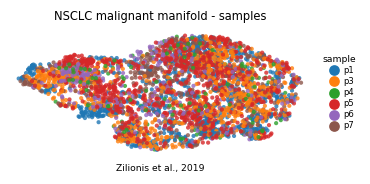

In [ ]:
# DELIVERABLE samples.pdf -- house (3.5,1.5) trajectory-panel style; colour = sample (Gate-1 evidence)
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('NSCLC malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])
fig